### Load models


In [1]:
import os
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from tqdm import tqdm
from matplotlib import rc

sys.path.append("../")
# Import dataloaders
import data_utils.ood_detection.cifar10 as cifar10
import data_utils.ood_detection.cifar100 as cifar100
import data_utils.ood_detection.lsun as lsun
import data_utils.ood_detection.svhn as svhn
import data_utils.ood_detection.mnist as mnist
import data_utils.ood_detection.tiny_imagenet as tiny_imagenet

# Network architectures
from net.lenet import lenet
from net.resnet import resnet50
from net.vgg import vgg16
from net.wide_resnet import wrn

from utils.gmm_utils import get_embeddings, gmm_evaluate, gmm_fit, maxp_evaluate, gmm_evaluate_with_perturbation, maxp_evaluate_with_perturbation
from metrics.uncertainty_confidence import entropy, logsumexp, confidence, sumexp,mutual_information_prob
from metrics.ood_metrics import get_roc_auc, get_roc_auc_logits

In [2]:
device = torch.device("cuda:0")
# Dataset params
dataset_num_classes = {"cifar10": 10, "cifar100": 100, "svhn": 10, "lsun": 10, "tiny_iamgenet": 200}
dataset_loader = {"cifar10": cifar10, "cifar100": cifar100, "SVHN": svhn, "mnist": mnist, "LSUN": lsun, "tiny_imagenet": tiny_imagenet}

# Mapping model name to model function
models = {
    "lenet": lenet,
    "resnet50": resnet50,
    "wide_resnet": wrn,
    "vgg16": vgg16,
}

model_to_num_dim = {"resnet18": 512, "resnet50": 2048, "resnet101": 2048, "resnet152": 2048, "wide_resnet": 640, "vgg16": 512}

batch_size = 256
dataset = "cifar10"
dataset_root = "../data"

model = "resnet50"
saved_model_name = "/home/sq/YYM/dum/saved_models/run38/resnet50_sn_3.0_mod_seed_1/2024_11_28_12_13_59/resnet50_sn_3.0_mod_seed_1_best.model"

# Taking input for the dataset
num_classes = dataset_num_classes[dataset]
test_loader = dataset_loader[dataset].get_test_loader(root=dataset_root, batch_size=batch_size)

In [3]:
#load model
print(f"load {saved_model_name}")
net = models[model](
    spectral_normalization=True,
    mod=True,
    num_classes=num_classes,
    temp=1.0,
).to(device)

_  = net.load_state_dict(torch.load(str(saved_model_name), map_location=device), strict=True)
_ = net.eval()

load /home/sq/YYM/dum/saved_models/run38/resnet50_sn_3.0_mod_seed_1/2024_11_28_12_13_59/resnet50_sn_3.0_mod_seed_1_best.model


In [4]:
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']

sns.set_style('whitegrid')
sns.set_context("paper", font_scale=1, rc={"lines.linewidth": 2.5})

rc('text', usetex=False)

def plot_activation(data1, data2, title1, title2):
    # 使用matplotlib绘制特征图
    fig, axes = plt.subplots(2, 1)
    plt.tight_layout()
    minv = np.quantile(data1,0.01)
    maxv = np.quantile(data1,0.99)

    im1 = axes[0].imshow(data1, cmap='viridis')  # cmap参数指定色彩映射
    axes[0].set_title(title1)
    im1.set_clim(minv, maxv)
    im2 = axes[1].imshow(data2, cmap='viridis')  # cmap参数指定色彩映射
    im2.set_clim(minv, maxv)
    axes[1].set_title(title2)

    fig.colorbar(im1, ax=axes)


if not os.path.exists(f"pngs/{model}/"):
    os.makedirs(f"pngs/{model}/")

In [5]:
num_samples = len(test_loader.dataset)
logits_N_C = torch.zeros((num_samples, num_classes), dtype=torch.float, device=device)
labels_N = torch.zeros(num_samples, dtype=torch.int, device=device)
preds_N = torch.zeros(num_samples, dtype=torch.int, device=device)
epsilons = [0,0.1,0.3,1] #加噪声强度
aus = []
with torch.no_grad():
    start = 0
    total = 0
    for epsilon in epsilons:
        tmp = []
        for data, label in tqdm(test_loader, dynamic_ncols=True):
            data = data.to(device)
            noise = torch.randn_like(data) * epsilon
            data = data+noise
            logits = net(data)
            probs = F.softmax(logits,dim=1)
            # print(probs.shape)
            au = entropy(logits)
            
            tmp.append(au)
        
        aus.append(torch.cat(tmp,dim=0).detach().cpu().numpy())

100%|██████████| 4/4 [00:00<00:00,  6.81it/s]


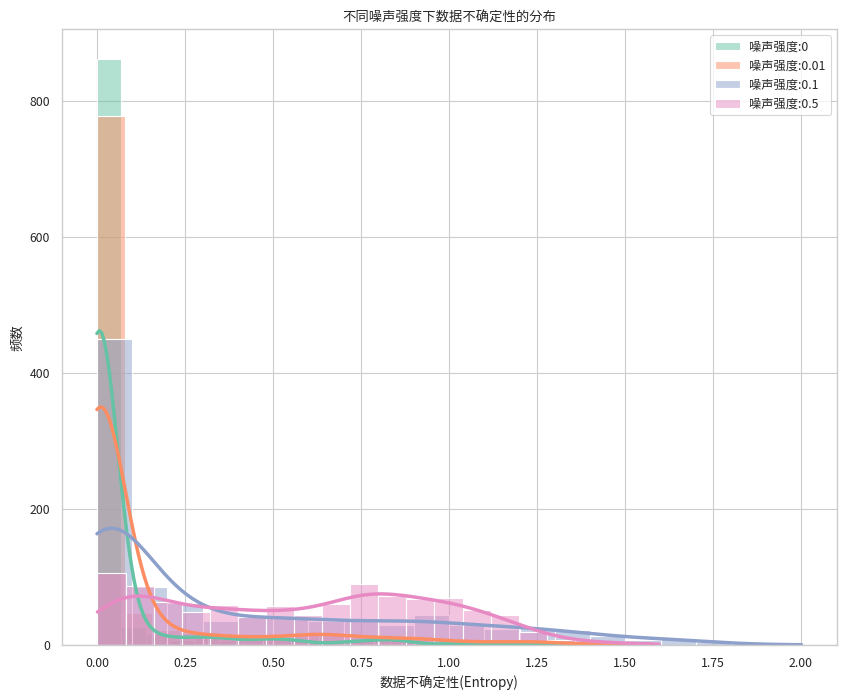

In [15]:
from matplotlib import rcParams,font_manager
import matplotlib
font_path = './fonts/NotoSansCJK-Regular.ttc'
font_prop = font_manager.FontProperties(fname=font_path)

matplotlib.rcParams['font.family'] = font_prop.get_name()
matplotlib.rcParams['axes.unicode_minus'] = False  # 防止负号显示问题

plt.figure(figsize=(10, 8))

# 使用 sns.histplot 绘制直方图，并显示 KDE 曲线
epsilons = [0,0.01,0.1,0.5] #加噪声强度
for i, epsilon in enumerate(epsilons):
    sns.histplot(aus[i], kde=True, bins=20, alpha=0.5, label=f'噪声强度:{epsilon}', color=sns.color_palette("Set2")[i])

# 添加图例和标签
plt.legend(loc='upper right')
plt.title('不同噪声强度下数据不确定性的分布')
plt.xlabel('数据不确定性(Entropy)')
plt.ylabel('频  数')

# 显示图形
plt.savefig("pngs/aleatoric.pdf",dpi=600)
plt.show()

In [31]:
data = {0:aus[0].tolist(),0.01:aus[1].tolist(),0.1:aus[2].tolist(),1:aus[3].tolist()}
import json

# 将字典存储到文件
with open("results/aletoricdata.json", "w") as f:
    json.dump(data, f, indent=4)  # 